In [ ]:
"""Bài thực hành 2 — Pima Indians Diabetes"""

In [1]:
"""Nhiệm vụ 1: Khám phá dữ liệu"""
"""Import thư viện"""
import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
"""Đọc dữ liệu"""
df_diabetes = pd.read_csv("diabetes.csv")

# Hiển thị dữ liệu
display(df_diabetes.head())

# Kích thước dữ liệu
print("Số dòng, số cột:", df_diabetes.shape)

# Thông tin dữ liệu
df_diabetes.info()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Số dòng, số cột: (768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [3]:
"""Kiểm tra dữ liệu tổng quan"""
# Thống kê mô tả cơ bản
display(df_diabetes.describe())

# Kiểm tra giá trị thiếu
print("Số giá trị thiếu từng cột:")
print(df_diabetes.isnull().sum())

# Kiểm tra dữ liệu trùng lặp
print("Số dòng trùng lặp:", df_diabetes.duplicated().sum())

# Kiểm tra số lượng từng nhóm kết quả
print(df_diabetes["Outcome"].value_counts())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Số giá trị thiếu từng cột:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Số dòng trùng lặp: 0
Outcome
0    500
1    268
Name: count, dtype: int64


In [4]:
"""Tính mean, median, mode, variance, standard deviation, range, percentile, quartile và IQR"""
# Lấy các cột dữ liệu số
numeric_diabetes = df_diabetes.select_dtypes(
    include=np.number
)

# Mean
mean_diabetes = np.mean(numeric_diabetes, axis=0)

# Median
median_diabetes = np.median(numeric_diabetes, axis=0)

# Mode
mode_diabetes = numeric_diabetes.mode().iloc[0]

# Variance: phương sai mẫu
variance_diabetes = np.var(
    numeric_diabetes,
    axis=0,
    ddof=1
)

# Standard deviation: độ lệch chuẩn mẫu
std_diabetes = np.std(
    numeric_diabetes,
    axis=0,
    ddof=1
)

# Range
range_diabetes = (
    np.max(numeric_diabetes, axis=0)
    - np.min(numeric_diabetes, axis=0)
)

# Percentile
percentile_diabetes = np.percentile(
    numeric_diabetes,
    [10, 25, 50, 75, 90],
    axis=0
)

# Quartiles
q1_diabetes = np.percentile(
    numeric_diabetes, 25, axis=0
)

q2_diabetes = np.percentile(
    numeric_diabetes, 50, axis=0
)

q3_diabetes = np.percentile(
    numeric_diabetes, 75, axis=0
)

# Interquartile Range
iqr_diabetes = q3_diabetes - q1_diabetes

# Tổng hợp kết quả
stats_diabetes = pd.DataFrame({
    "Mean": mean_diabetes,
    "Median": median_diabetes,
    "Mode": mode_diabetes,
    "Variance": variance_diabetes,
    "Standard Deviation": std_diabetes,
    "Range": range_diabetes,
    "Q1": q1_diabetes,
    "Q2 (Median)": q2_diabetes,
    "Q3": q3_diabetes,
    "IQR": iqr_diabetes
}, index=numeric_diabetes.columns)

display(stats_diabetes.round(4))

,Mean,Median,Mode,Variance,Standard Deviation,Range,Q1,Q2 (Median),Q3,IQR
Pregnancies,3.8451,3.0000,1.000,11.3541,3.3696,17.000,1.0000,3.0000,6.0000,5.0000
Glucose,120.8945,117.0000,99.000,1022.2483,31.9726,199.000,99.0000,117.0000,140.2500,41.2500
BloodPressure,69.1055,72.0000,70.000,374.6473,19.3558,122.000,62.0000,72.0000,80.0000,18.0000
SkinThickness,20.5365,23.0000,0.000,254.4732,15.9522,99.000,0.0000,23.0000,32.0000,32.0000
Insulin,79.7995,30.5000,0.000,13281.1801,115.2440,846.000,0.0000,30.5000,127.2500,127.2500
BMI,31.9926,32.0000,32.000,62.1600,7.8842,67.100,27.3000,32.0000,36.6000,9.3000
DiabetesPedigreeFunction,0.4719,0.3725,0.254,0.1098,0.3313,2.342,0.2438,0.3725,0.6262,0.3825
Age,33.2409,29.0000,22.000,138.3030,11.7602,60.000,24.0000,29.0000,41.0000,17.0000
Outcome,0.3490,0.0000,0.000,0.2275,0.4770,1.000,0.0000,0.0000,1.0000,1.0000


In [5]:
"""Bảng percentile riêng"""
percentile_table_diabetes = pd.DataFrame(
    percentile_diabetes.T,
    index=numeric_diabetes.columns,
    columns=["P10", "P25", "P50", "P75", "P90"]
)

display(percentile_table_diabetes.round(4))

,P10,P25,P50,P75,P90
Pregnancies,0.000,1.0000,3.0000,6.0000,9.0000
Glucose,85.000,99.0000,117.0000,140.2500,167.0000
BloodPressure,54.000,62.0000,72.0000,80.0000,88.0000
SkinThickness,0.000,0.0000,23.0000,32.0000,40.0000
Insulin,0.000,0.0000,30.5000,127.2500,210.0000
BMI,23.600,27.3000,32.0000,36.6000,41.5000
DiabetesPedigreeFunction,0.165,0.2438,0.3725,0.6262,0.8786
Age,22.000,24.0000,29.0000,41.0000,51.0000
Outcome,0.000,0.0000,0.0000,1.0000,1.0000


In [6]:
"""Tính thống kê"""
for column in numeric_diabetes.columns:
    values = numeric_diabetes[column].dropna()

    mode_result = stats.mode(
        values,
        keepdims=False
    )

    print(f"\nCột: {column}")
    print("Mean:", stats.tmean(values))
    print("Median:", np.median(values))
    print("Mode:", mode_result.mode)
    print("Mode count:", mode_result.count)
    print("Variance:", stats.tvar(values))
    print("Standard deviation:", stats.tstd(values))
    print("Range:", np.ptp(values))
    print("Percentiles:", np.percentile(
        values, [10, 25, 50, 75, 90]
    ))
    print("IQR:", stats.iqr(values))


Cột: Pregnancies
Mean: 3.8450520833333335
Median: 3.0
Mode: 1
Mode count: 135
Variance: 11.354056320621467
Standard deviation: 3.3695780626988694
Range: 17
Percentiles: [0. 1. 3. 6. 9.]
IQR: 5.0

Cột: Glucose
Mean: 120.89453125
Median: 117.0
Mode: 99
Mode count: 17
Variance: 1022.2483142519557
Standard deviation: 31.97261819513622
Range: 199
Percentiles: [ 85.    99.   117.   140.25 167.  ]
IQR: 41.25

Cột: BloodPressure
Mean: 69.10546875
Median: 72.0
Mode: 70
Mode count: 57
Variance: 374.64727122718386
Standard deviation: 19.35580717064478
Range: 122
Percentiles: [54. 62. 72. 80. 88.]
IQR: 18.0

Cột: SkinThickness
Mean: 20.536458333333332
Median: 23.0
Mode: 0
Mode count: 227
Variance: 254.47324532811825
Standard deviation: 15.952217567727637
Range: 99
Percentiles: [ 0.  0. 23. 32. 40.]
IQR: 32.0

Cột: Insulin
Mean: 79.79947916666667
Median: 30.5
Mode: 0
Mode count: 374
Variance: 13281.18007795524
Standard deviation: 115.24400235133818
Range: 846
Percentiles: [  0.     0.    30.5  127

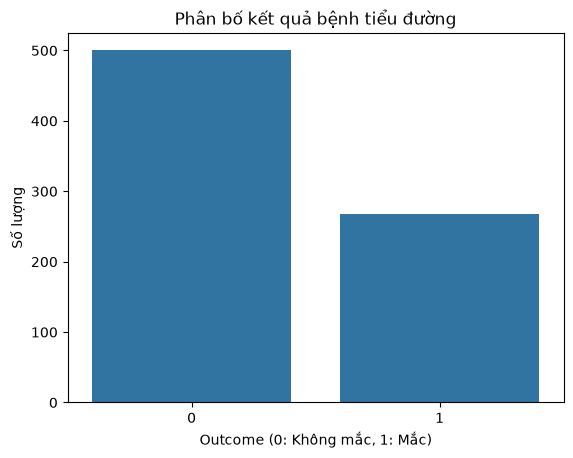

In [7]:
"""Trực quan hóa dữ liệu"""
# Phân bố nhóm Outcome
sns.countplot(data=df_diabetes, x="Outcome")

plt.title("Phân bố kết quả bệnh tiểu đường")
plt.xlabel("Outcome (0: Không mắc, 1: Mắc)")
plt.ylabel("Số lượng")
plt.show()

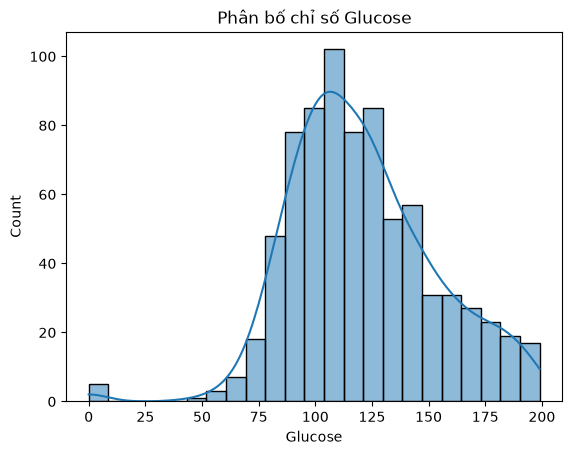

In [8]:
# Phân bố Glucose
sns.histplot(
    data=df_diabetes,
    x="Glucose",
    kde=True
)

plt.title("Phân bố chỉ số Glucose")
plt.show()

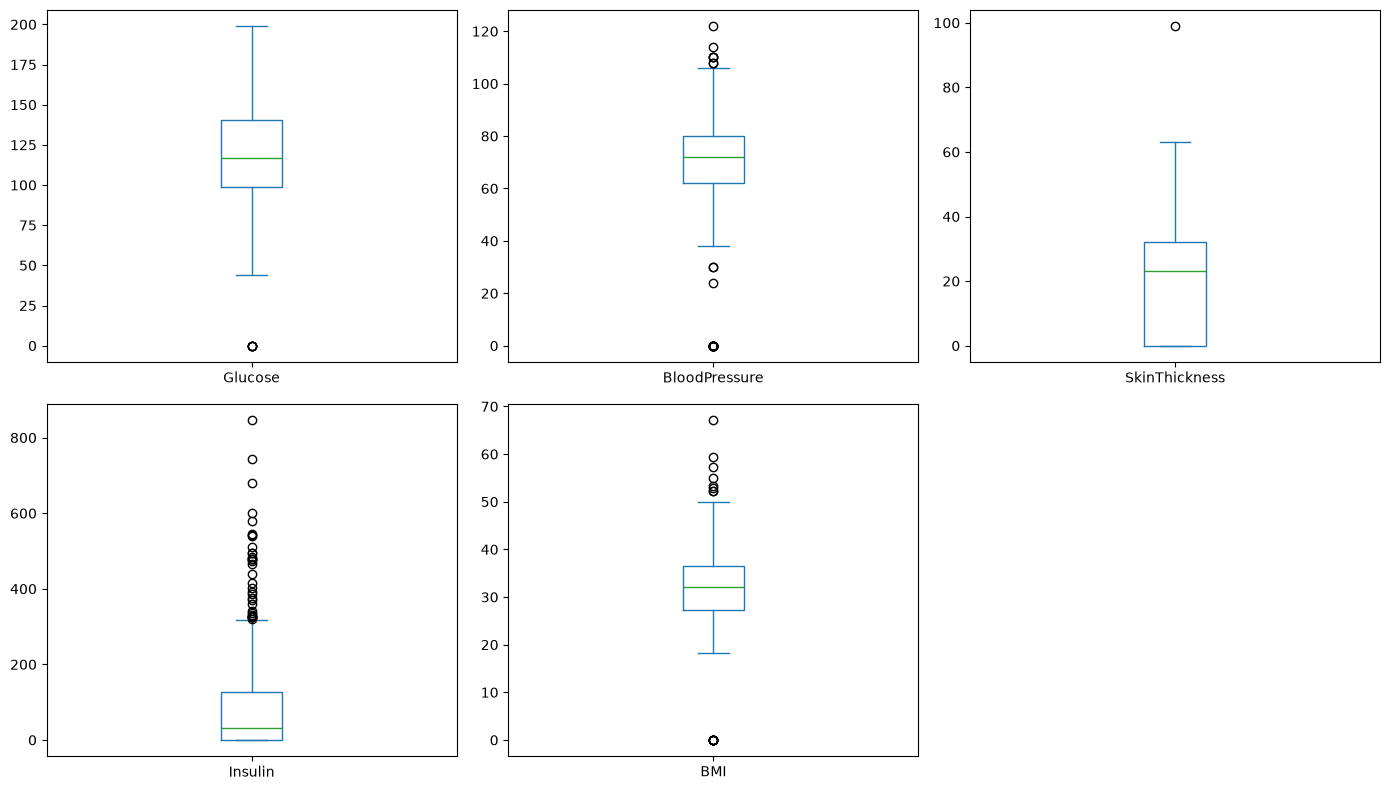

In [9]:
# Boxplot của một số chỉ số sức khỏe
columns_to_plot = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_diabetes[columns_to_plot].plot(
    kind="box",
    subplots=True,
    layout=(2, 3),
    figsize=(14, 8),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [ ]:
"""Nhiệm vụ 2: Khám phá và xử lý dữ liệu"""

In [11]:
"""Kiểm tra dữ liệu trước khi xử lý"""
print("Kích thước ban đầu:", df_diabetes.shape)

print("\nKiểu dữ liệu:")
print(df_diabetes.dtypes)

print("\nDữ liệu thiếu:")
print(df_diabetes.isnull().sum())

print("\nDòng trùng lặp:")
print(df_diabetes.duplicated().sum())

display(df_diabetes.head())

Kích thước ban đầu: (768, 9)

Kiểu dữ liệu:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Dữ liệu thiếu:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Dòng trùng lặp:
0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
"""Loại bỏ dữ liệu trùng lặp"""
df_diabetes = df_diabetes.drop_duplicates().copy()

df_diabetes = df_diabetes.reset_index(drop=True)

print("Kích thước sau khi loại bỏ trùng lặp:")
print(df_diabetes.shape)

print("Số dòng trùng lặp còn lại:")
print(df_diabetes.duplicated().sum())

Kích thước sau khi loại bỏ trùng lặp:
(768, 9)
Số dòng trùng lặp còn lại:
0


In [13]:
"""Thay thế dữ liệu và thay đổi định dạng"""
# Chuyển các cột về kiểu số
for column in df_diabetes.columns:
    df_diabetes[column] = pd.to_numeric(
        df_diabetes[column],
        errors="coerce"
    )

# Các cột mà giá trị 0 cần được xem xét như dữ liệu thiếu
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Đếm số giá trị 0 trước khi thay thế
print("Số giá trị 0 trước xử lý:")
print((df_diabetes[zero_as_missing] == 0).sum())

# Thay thế 0 bằng NaN
df_diabetes[zero_as_missing] = (
    df_diabetes[zero_as_missing].replace(0, np.nan)
)

print("\nSố giá trị thiếu sau khi thay thế:")
print(df_diabetes.isnull().sum())

Số giá trị 0 trước xử lý:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Số giá trị thiếu sau khi thay thế:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [14]:
"""Xử lý dữ liệu thiếu bằng trung vị"""
# Xem số lượng giá trị thiếu trước khi xử lý
print("Thiếu trước xử lý:")
print(df_diabetes.isnull().sum())

# Thay giá trị thiếu của các cột số bằng trung vị
numeric_columns = df_diabetes.select_dtypes(
    include=np.number
).columns

for column in numeric_columns:
    df_diabetes[column] = df_diabetes[column].fillna(
        df_diabetes[column].median()
    )

# Kiểm tra lại
print("\nThiếu sau xử lý:")
print(df_diabetes.isnull().sum())

print("\nKích thước dữ liệu sau xử lý:")
print(df_diabetes.shape)

Thiếu trước xử lý:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Thiếu sau xử lý:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Kích thước dữ liệu sau xử lý:
(768, 9)


In [15]:
"""Kiểm tra dữ liệu sau xử lý"""
# Xem 5 dòng đầu
display(df_diabetes.head())

# Kiểm tra kiểu dữ liệu
df_diabetes.info()

# Thống kê mô tả sau xử lý
display(df_diabetes.describe())

# Kiểm tra giá trị thiếu còn lại
print("Tổng giá trị thiếu:", df_diabetes.isnull().sum().sum())

# Kiểm tra trùng lặp
print("Số dòng trùng lặp:", df_diabetes.duplicated().sum())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    float64
 2   BloodPressure             768 non-null    float64
 3   SkinThickness             768 non-null    float64
 4   Insulin                   768 non-null    float64
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(6), int64(3)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Tổng giá trị thiếu: 0
Số dòng trùng lặp: 0


In [16]:
"""Lưu dữ liệu đã xử lý"""
df_diabetes.to_csv(
    "diabetes_cleaned.csv",
    index=False
)

print("Đã lưu file diabetes_cleaned.csv")

Đã lưu file diabetes_cleaned.csv
